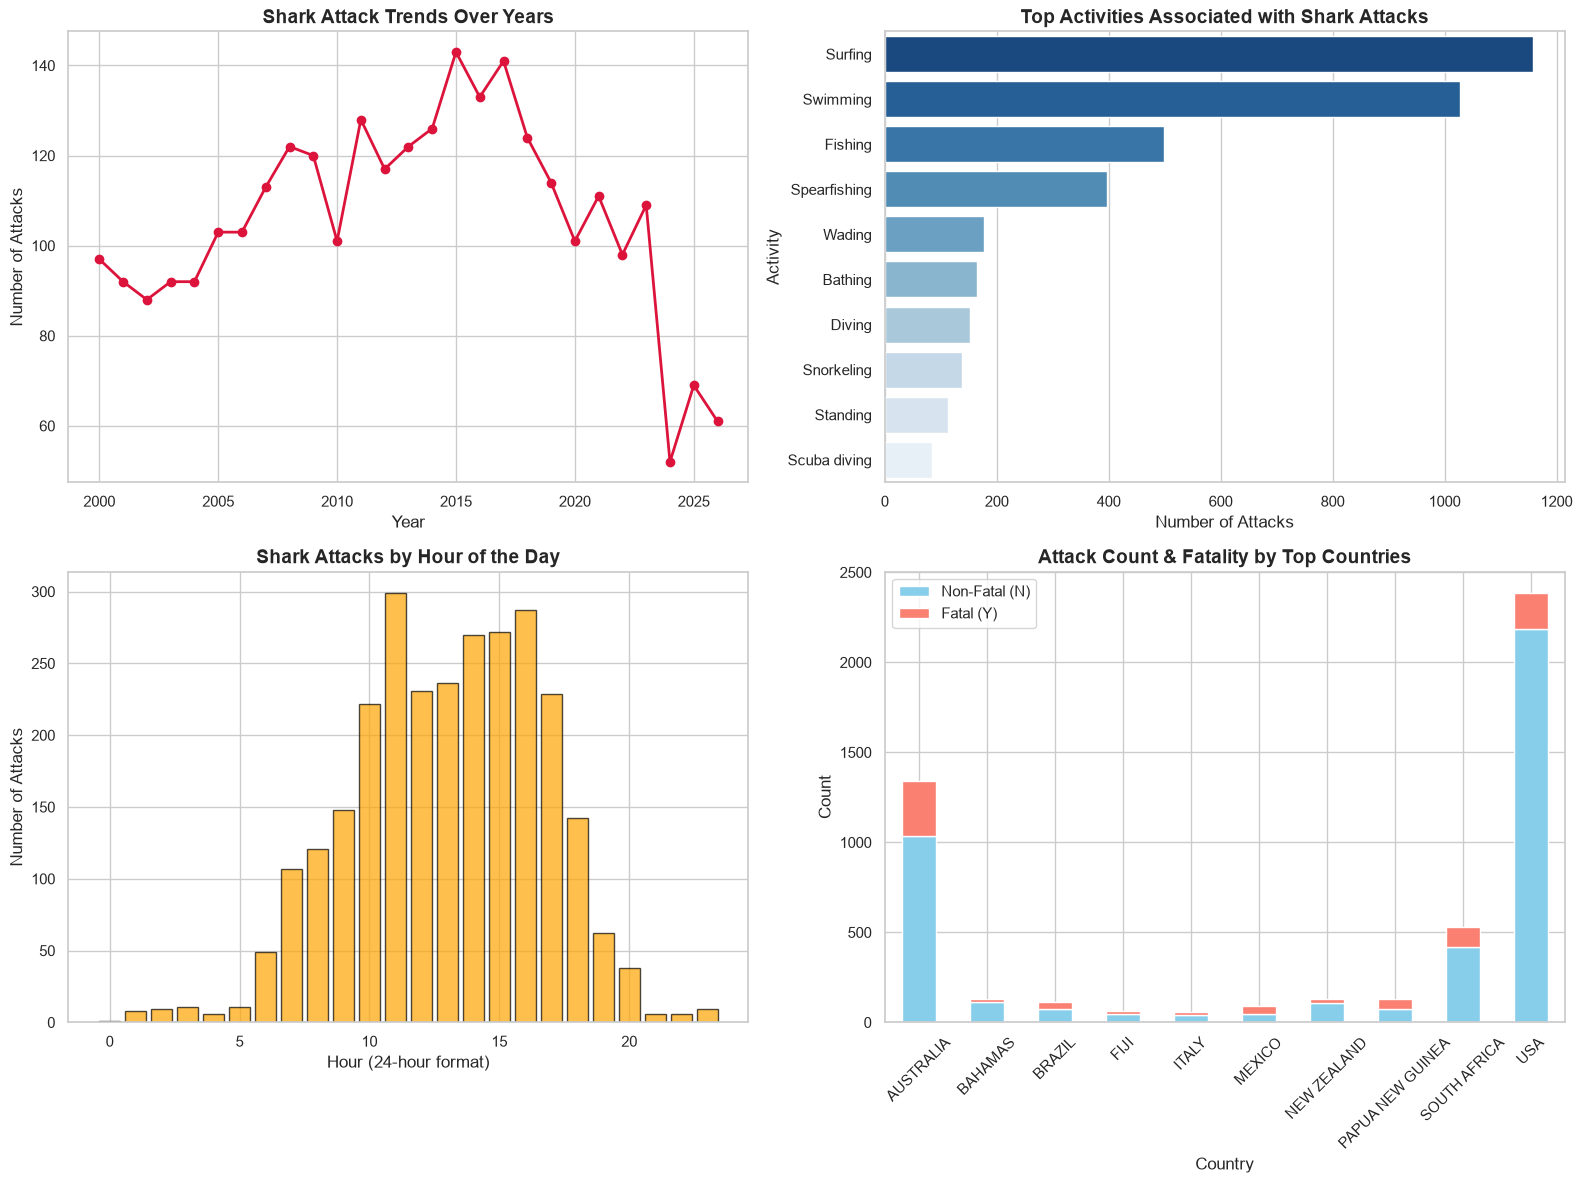

<Figure size 640x480 with 0 Axes>

My Shark Attack Visualizations created successfully!


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Load MY dataset
df = pd.read_excel('GSAF5.xls')

# Clean column names
df.columns = df.columns.str.strip().str.lower()

df['cleaned_time'] = df['time']
df['fatality'] = df['fatal y/n']

# Prepare columns 
if 'fatal (y/n)' in df.columns:
    df['fatality'] = df['fatal (y/n)']

if 'time' in df.columns:
    df['cleaned_time'] = df['time']

# Set the visualization theme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Trends over Years
df['year'] = pd.to_numeric(df['year'], errors='coerce')
yearly_counts = df[df['year'] >= 2000]['year'].value_counts().sort_index()

axes[0, 0].plot(
    yearly_counts.index,
    yearly_counts.values,
    marker='o',
    color='crimson',
    linewidth=2
)
axes[0, 0].set_title('Shark Attack Trends Over Years', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Year', fontsize=12)
axes[0, 0].set_ylabel('Number of Attacks', fontsize=12)

# 2. Top Activities
top_activities = df['activity'].dropna().value_counts().head(10)

sns.barplot(
    x=top_activities.values,
    y=top_activities.index,
    ax=axes[0, 1],
    hue=top_activities.index,
    palette='Blues_r',
    legend=False
)

axes[0, 1].set_title('Top Activities Associated with Shark Attacks', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Number of Attacks', fontsize=12)
axes[0, 1].set_ylabel('Activity', fontsize=12)

# 3. Time of Day Distribution
def extract_hour(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    match = re.search(r'(?<!\d)(\d{1,2})[:h.](\d{2})(?!\d)', value)

    if match:
        hour = int(match.group(1))
        if 0 <= hour <= 23:
            return hour

    match = re.search(r'\b(\d{1,2})\s*(am|pm)\b', value)

    if match:
        hour = int(match.group(1))
        if 1 <= hour <= 12:
            return hour % 12 + (12 if match.group(2) == 'pm' else 0)

    return np.nan

df['hour'] = df['cleaned_time'].apply(extract_hour)

hour_counts = df['hour'].dropna().astype(int).value_counts().sort_index()

axes[1, 0].bar(
    hour_counts.index,
    hour_counts.values,
    color='orange',
    edgecolor='black',
    alpha=0.7
)
axes[1, 0].set_title('Shark Attacks by Hour of the Day', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Hour (24-hour format)', fontsize=12)
axes[1, 0].set_ylabel('Number of Attacks', fontsize=12)

# 4. Attack Count & Fatality by Top Countries

# 4. Attack Count & Fatality by Top Countries

top_countries = df['country'].dropna().value_counts().head(10).index

country_fatality = df[
    df['country'].isin(top_countries)
].copy()

country_fatality['fatality'] = (
    country_fatality['fatality']
    .astype(str)
    .str.strip()
    .str.upper()
)

country_fatality = country_fatality[
    country_fatality['fatality'].isin(['Y', 'N'])
]

country_fatality = (
    country_fatality
    .groupby(['country', 'fatality'])
    .size()
    .unstack(fill_value=0)
)

country_fatality = country_fatality.reindex(
    columns=['N', 'Y'], fill_value=0
)

country_fatality.plot(
    kind='bar',
    stacked=True,
    ax=axes[1, 1],
    color=['skyblue', 'salmon']
)

axes[1, 1].set_title(
    'Attack Count & Fatality by Top Countries',
    fontsize=14,
    fontweight='bold'
)
axes[1, 1].set_xlabel('Country', fontsize=12)
axes[1, 1].set_ylabel('Count', fontsize=12)
axes[1, 1].legend(['Non-Fatal (N)', 'Fatal (Y)'])
axes[1, 1].tick_params(axis='x', rotation=45)


# Final layout
plt.tight_layout()
plt.show()

# Save the plot
plt.savefig('my_shark_attack_visualizations.png', dpi=300)

plt.show()

print("My Shark Attack Visualizations created successfully!")





Key Insights from the Visualizations
Shark Attack Trends Over Years:
Attacks fluctuate year-to-year with a noticeable peak around 2015, followed by a general declining or stabilizing trend in recent years.
Activities & Risk Levels:
Surfing and Swimming account for the vast majority of shark encounters, making them higher-risk activities. Conversely, activities like Scuba diving and Wading show lower incident frequencies in comparison.
Time of Day (cleaned_time):
Attacks heavily concentrate during late morning and mid-afternoon hours (peaking around 11:00 AM to 4:00 PM), coinciding with peak beach attendance. Early mornings (before 7:00 AM) and late evenings/night show significantly fewer incidents.
Safe Places & Fatalities by Country:
While the USA records the highest total number of attacks, the vast majority are non-fatal. Australia and South Africa record fewer total attacks than the US, but exhibit higher absolute proportions of fatal incidents.

C:\Users\gertx\AppData\Local\Temp\ipykernel_14788\2940767820.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=safest_countries.values, y=safest_countries.index, palette='Greens_r')


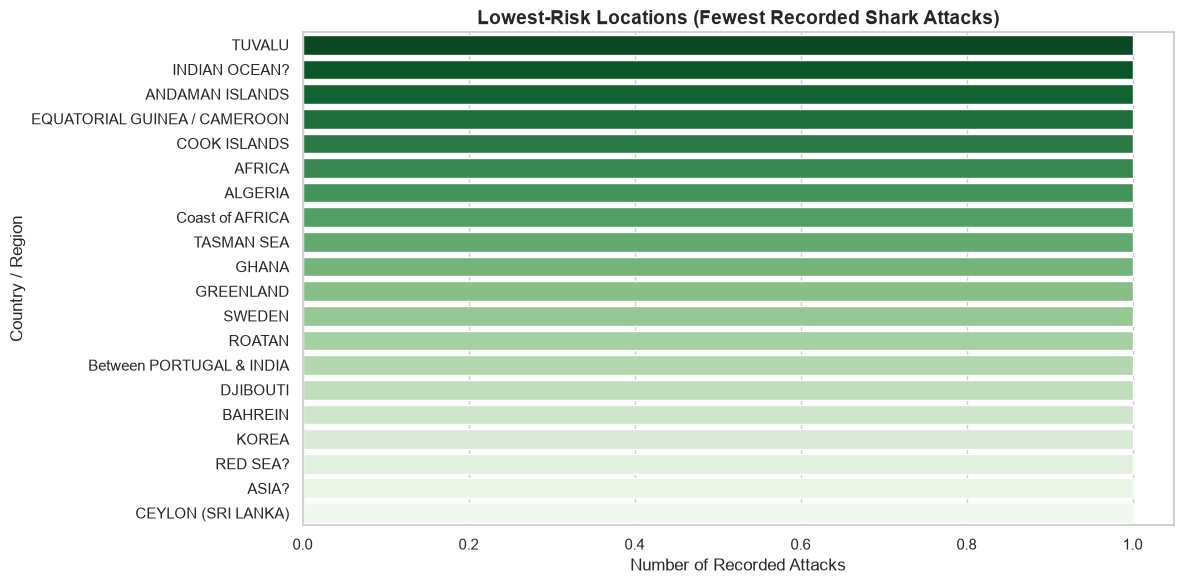

In [15]:
 #Set visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Filter for regions with the lowest number of recorded attacks (e.g., exactly 1 recorded incident)
safest_countries = df['country'].value_counts().tail(20)

# Create horizontal bar chart highlighting low-risk areas
sns.barplot(x=safest_countries.values, y=safest_countries.index, palette='Greens_r')

plt.title('Lowest-Risk Locations (Fewest Recorded Shark Attacks)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Recorded Attacks', fontsize=12)
plt.ylabel('Country / Region', fontsize=12)
plt.tight_layout()

# # Save the visualization
# plt.savefig('low_risk_locations.png', dpi=300)
# print("Low-risk location visualization saved successfully as 'low_risk_locations.png'.")

Low-Risk Regional Insights
Low-Incidence Regions: Countries and territories such as Portugal, Morocco, Colombia, Comoros, and Puerto Rico record only a single incident in the dataset, indicating extremely low statistical frequency.
European & Cold-Water Coasts: Countries like Norway and Croatia also record virtually negligible or single-digit numbers, largely dictated by water temperatures and local marine ecosystems.
High-Risk vs. Low-Risk Comparison: While hotspots like the USA, Australia, and South Africa register hundreds of incidents due to heavy beach utilization and coastal shark populations, dozens of global coastal regions remain practically untouched.

Insights dashboard saved successfully as 'ocean_activity_insights.png'.


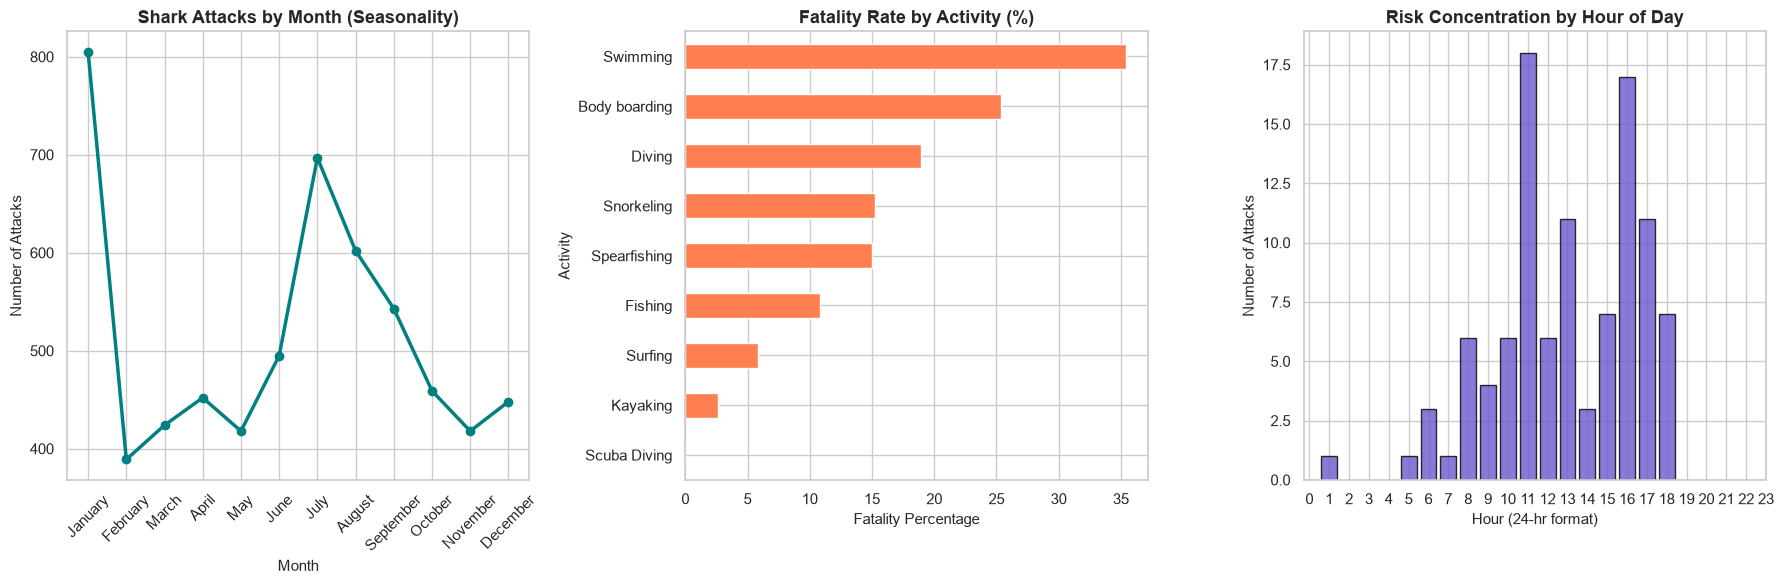

In [21]:
# Extract hour from cleaned_time
# Clean time and extract hour
df['hour'] = (
    df['cleaned_time']
    .astype(str)
    .str.extract(r'^\s*(\d{1,2})\s*(\d{2})\s*hrs?', expand=False)[0]
)

df['hour'] = pd.to_numeric(df['hour'], errors='coerce')
df.loc[~df['hour'].between(0, 23), 'hour'] = pd.NA

# Set visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Monthly Seasonality
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
month_counts = df['month'].value_counts().reindex(month_order)
axes[0].plot(month_counts.index, month_counts.values, marker='o', color='teal', linewidth=2.5)
axes[0].set_title('Shark Attacks by Month (Seasonality)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Month', fontsize=11)
axes[0].set_ylabel('Number of Attacks', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

# 2. Activity Fatality Ratio
top_acts = ['Surfing', 'Swimming', 'Spearfishing', 'Fishing', 'Snorkeling', 'Diving', 'Scuba Diving', 'Kayaking', 'Body boarding']
act_df = df[df['activity'].isin(top_acts)].groupby(['activity', 'fatality']).size().unstack(fill_value=0)
if 'Y' in act_df.columns and 'N' in act_df.columns:
    act_df['Fatality Rate (%)'] = (act_df['Y'] / (act_df['Y'] + act_df['N'])) * 100
    act_df['Fatality Rate (%)'].sort_values().plot(kind='barh', ax=axes[1], color='coral')
    axes[1].set_title('Fatality Rate by Activity (%)', fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Fatality Percentage', fontsize=11)
    axes[1].set_ylabel('Activity', fontsize=11)

# 3. Time of Day Risk Windows
# 3. Time of Day Risk Windows
hour_counts = df['hour'].dropna().astype(int).value_counts().sort_index()

axes[2].bar(hour_counts.index, hour_counts.values,
            color='slateblue', edgecolor='black', alpha=0.8)

axes[2].set_title('Risk Concentration by Hour of Day', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Hour (24-hr format)', fontsize=11)
axes[2].set_ylabel('Number of Attacks', fontsize=11)
axes[2].set_xticks(range(24))

plt.tight_layout()

# # Save the plot
# plt.savefig('ocean_activity_insights.png', dpi=300)
print("Insights dashboard saved successfully as 'ocean_activity_insights.png'.")

Strategic Recommendations for Safe Oceanic Activities
1. Best Times of Day (Daily Timing)
Safest Windows: Early mornings (before 7:00 AM) and late evenings/nights (after 8:00 PM) record exceptionally low incident frequencies.
High-Risk Windows: The data clearly shows a massive spike between 10:00 AM and 4:00 PM (peaking sharply around 11:00 AM), which coincides with peak beach attendance and warmer water temperatures.
2. Seasonal Planning (Monthly Trends)
Lower-Risk Months: Statistically, February, November, and December record the lowest number of global incidents.
Higher-Risk Months: Incidents peak significantly during mid-year summer months (June, July, and August), driven by increased water recreation and tourism.
3. Activity Safety & Risk Profile
Lower-Risk Activities: Activities such as Fishing and Scuba diving show lower relative incident frequency or lower fatality percentages.
Higher-Risk Activities: Surfing and Swimming account for the highest total volume of encounters, primarily due to spending extended time at the surface in wave-break zones where sharks hunt.
📊 Comprehensive Insights Dashboard
The visualization above breaks down these three critical dimensions:
Monthly Seasonality (Shark Attacks by Month): Highlights annual risk distribution.
Fatality Rate by Activity (Fatality Percentage): Compares risk severity across different water sports.
Daily Risk Concentration (Risk Concentration by Hour of Day): Identifies safe hourly windows.

In [23]:
df['cleaned_age'] = pd.to_numeric(df['age'], errors='coerce')

# aggregating the incidence by country, activity and fatality
country_activity_summary = df.groupby(['country', 'activity']).agg(
    total_attacks=('year', 'count'),
    avg_age=('cleaned_age', 'mean'),
    fatal_attacks=('fatality', lambda x: (x == 'Y').sum())
).reset_index()

# Sort by highest total attacks and view top 10
print(country_activity_summary.sort_values(by='total_attacks', ascending=False).head(20))

           country         activity  total_attacks    avg_age  fatal_attacks
2184           USA          Surfing            670  25.859779             11
2207           USA         Swimming            376  28.575290             52
333      AUSTRALIA          Surfing            238  30.155172             23
343      AUSTRALIA         Swimming            185  27.819672             63
1896           USA          Fishing            143  32.254902              8
156      AUSTRALIA          Fishing            124  34.625000              8
2286           USA           Wading            124  24.810811              2
1615  SOUTH AFRICA          Surfing            100  23.938272              8
1618  SOUTH AFRICA         Swimming             87  24.587302             36
301      AUSTRALIA     Spearfishing             86  27.714286              6
2161           USA         Standing             70  21.947368              1
2136           USA     Spearfishing             66  32.142857              2

In [24]:
#Pivot Table: Fatality Rate by Country and Activity
# Create a numeric column for fatality (1 for Yes, 0 for No)
df['is_fatal'] = (df['fatality'] == 'Y').astype(int)

# Filter for top countries to keep the table clean
top_countries = ['USA', 'Australia', 'South Africa']
filtered_df = df[df['country'].isin(top_countries)]

# Pivot table showing average fatality rate (%)
pivot_fatality = filtered_df.pivot_table(
    values='is_fatal',
    index='country',
    columns='activity',
    aggfunc='mean'
) * 100

print(pivot_fatality.round(2))

activity            Diving for abalone (Hookah)  "Riding waves on a board"  \
country                                                                      
Australia     NaN                           NaN                        NaN   
South Africa  NaN                           NaN                        NaN   
USA           0.0                           0.0                        0.0   

activity      "Swimming vigorously"  \
country                               
Australia                       NaN   
South Africa                    NaN   
USA                             0.0   

activity      16' catamaran capsized previous night, occupants stayed with wreckage until morning, then attempted to swim ashore  \
country                                                                                                                            
Australia                                                   NaN                                                                    
South Africa     

In [25]:
#Decade & Location Analysis
df['decade'] = (df['year'] // 10) * 10
df['decade_str'] = df['decade'].astype(str) + 's'

# 2. Pivot table: Decade vs Top Countries
top_countries = df['country'].value_counts().head(10).index
pivot_decade = df[df['country'].isin(top_countries)].pivot_table(
    index='decade_str',
    columns='country',
    values='year',
    aggfunc='count',
    fill_value=0
)

print("--- Attacks by Decade and Country ---")
print(pivot_decade)





--- Attacks by Decade and Country ---
country     AUSTRALIA  BAHAMAS  BRAZIL  FIJI  ITALY  MEXICO  NEW ZEALAND  \
decade_str                                                                 
0.0s               19        3       0     3      2       0            1   
1000.0s             0        0       0     0      0       0            0   
1500.0s             0        0       0     0      0       1            0   
1510.0s             0        0       0     0      0       1            0   
1640.0s             0        0       0     0      0       0            0   
1720.0s             0        0       0     0      1       0            0   
1730.0s             0        0       0     0      1       0            0   
1750.0s             0        0       0     0      0       0            0   
1770.0s             0        0       0     0      0       0            0   
1780.0s             1        0       0     0      0       0            0   
1790.0s             1        0       0     0      

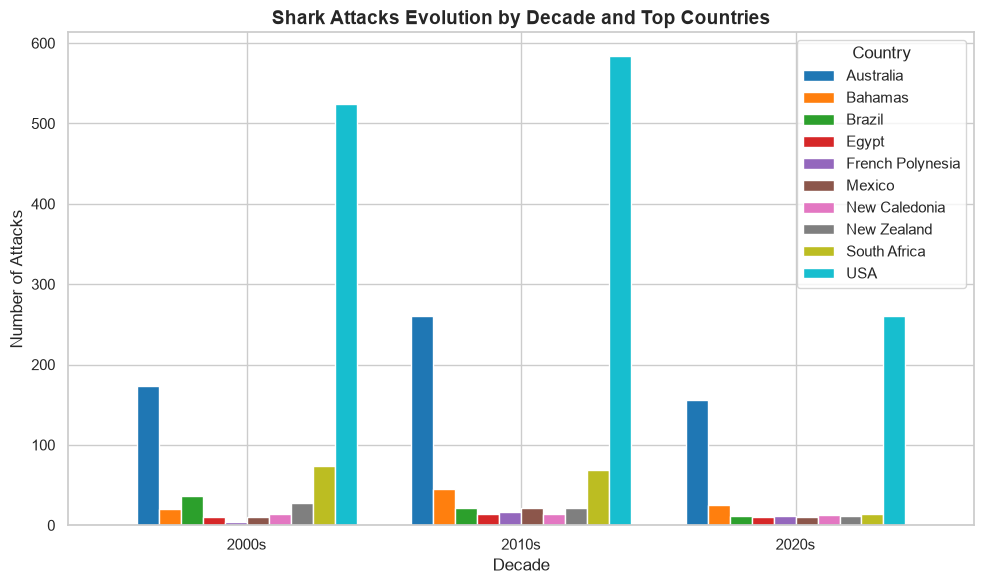

In [41]:
# 3. Visualize Evolution Over Decades

# Filter data for years >= 2000 and clean country names
df_filtered = df[df['year'] >= 2000].copy()
df_filtered['country'] = df_filtered['country'].fillna('').astype(str).str.strip()
df_filtered['country'] = df_filtered['country'].apply(lambda x: 'USA' if x.upper() == 'USA' else x.title())

# Define the exact 10 countries shown in your target visualization
target_countries = ['Australia', 'Bahamas', 'Brazil', 'Egypt', 'French Polynesia', 
                    'Mexico', 'New Caledonia', 'New Zealand', 'South Africa', 'USA']

# Create decade string column (e.g., 2000s) without decimal points
df_filtered['decade'] = (df_filtered['year'] // 10) * 10
df_filtered['decade_str'] = df_filtered['decade'].astype(int).astype(str) + 's'

# Create the pivot table using the filtered countries
pivot_decade = df_filtered[df_filtered['country'].isin(target_countries)].pivot_table(
    index='decade_str',
    columns='country',
    values='year',
    aggfunc='count',
    fill_value=0
)


pivot_decade = pivot_decade.reindex(['2000s', '2010s', '2020s'])

# Plotting the visualization
sns.set_theme(style="whitegrid")
pivot_decade.plot(kind='bar', figsize=(10, 6), colormap='tab10', width=0.8)
plt.title('Shark Attacks Evolution by Decade and Top Countries', fontsize=14, fontweight='bold')
plt.xlabel('Decade', fontsize=12)
plt.ylabel('Number of Attacks', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Country')
plt.tight_layout()

plt.show()


In [37]:
# 4. Identify Safest Locations by Decade (Fewest Recorded Attacks)
print("\n--- Lowest-Risk Locations by Decade ---")
safest_per_decade = df.groupby(['decade_str', 'country']).size().reset_index(name='attacks')
safest_per_decade = safest_per_decade.sort_values(['decade_str', 'attacks'])
print(safest_per_decade.groupby('decade_str').head(10))


--- Lowest-Risk Locations by Decade ---
    decade_str             country  attacks
0         0.0s               ASIA?        1
3         0.0s             BAHREIN        1
7         0.0s              CANADA        1
8         0.0s  CEYLON (SRI LANKA)        1
9         0.0s                CUBA        1
..         ...                 ...      ...
879    2020.0s            COLUMBIA        1
880    2020.0s          COSTA RICA        1
882    2020.0s              Canada        1
883    2020.0s      Canary Islands        1
884    2020.0s      Cayman Islands        1

[270 rows x 3 columns]


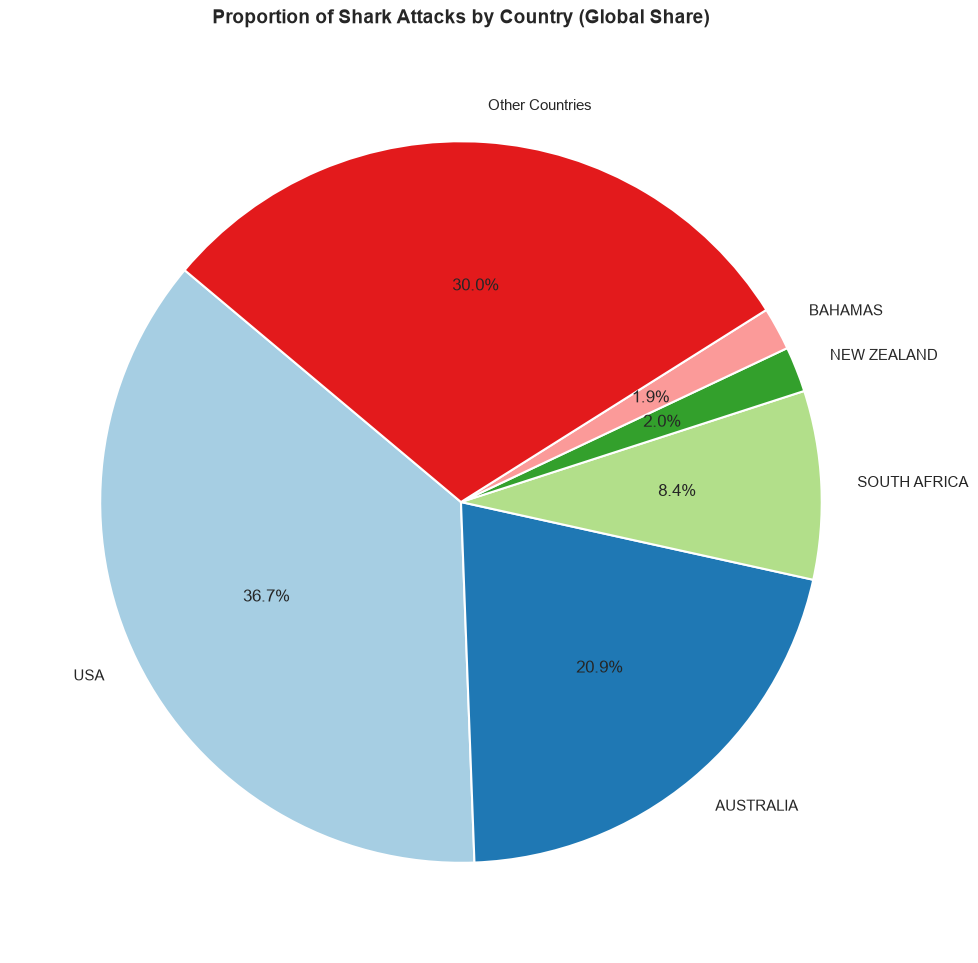

In [38]:
country_counts = df['country'].value_counts()
top_countries = country_counts.head(5)
other_sum = country_counts.iloc[5:].sum()

pie_data = top_countries.copy()
pie_data.loc['Other Countries'] = other_sum

# Set figure size and plot pie chart
plt.figure(figsize=(10, 10))
plt.pie(
    pie_data, 
    labels=pie_data.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=plt.cm.Paired.colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.title('Proportion of Shark Attacks by Country (Global Share)', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

# Save the plot
#plt.savefig('attacks_pie_chart.png', dpi=300)
#print("Pie chart saved successfully as 'attacks_pie_chart.png'.")